# VaDE 在 CIFAR-10 上的复现与 CNN 改造

**老师要求：** 将 [GuHY777/VaDE-pytorch](https://github.com/GuHY777/VaDE-pytorch) 的 MNIST 实验迁移至 CIFAR-10，并修改 encoder / decoder 的 CNN 架构。

本 Notebook 可独立运行，完整包含：数据 → 卷积 AE 预训练 → 对角 GMM 初始化 → VaDE 联合优化 → ACC/NMI/ARI 评估 → 重建、生成及潜空间可视化。没有使用有标签预训练模型；类别标签不进入损失或 GMM 拟合。

参考：Jiang et al., *Variational Deep Embedding: An Unsupervised and Generative Approach to Clustering*, IJCAI 2017，[论文](https://arxiv.org/abs/1611.05148)。这是一项 **CIFAR-10 迁移实验**，不等同于复现论文中 MNIST 的数值结果。

## 1. 改动与运行方式

原仓库的 `model.py` 实际采用全连接 MLP，并非 CNN。下面按老师要求替换整个图像编码/解码网络。

| 项目 | 原仓库 | 本 Notebook |
|---|---|---|
| 数据 | MNIST，展平 784 维 | CIFAR-10，保留 RGB 3×32×32 |
| Encoder | 784→500→500→2000→10 | 三层 stride=2 Conv2d → μ / log σ² |
| Decoder | 全连接 + Sigmoid | Linear → 三层 ConvTranspose2d → Sigmoid |
| 潜变量 / 簇数 | 10 / 10 | 10 / 10 |
| 预训练 / 初始化 | AE + 对角 GMM | 保留；方差头初始化为小方差 |
| 混合权重 | 直接优化 π，可能变负或不归一化 | 优化 logits，softmax 得到合法概率 |
| 重建分布 | BCE | 默认连续 RGB 的固定方差 Gaussian；可选 BCE 对照 |
| 数据协议 | 合并训练和测试数据做聚类 | 训练集拟合，测试集只做最终评估 |
| 预测 | 随机采样 z | 用 μ 的确定性责任度，便于重复比较 |
| 设备 / ACC | 强制 CUDA / 过时 sklearn API | CUDA、MPS、CPU / SciPy 匈牙利匹配 |

**从上到下运行所有单元格。当前默认配置为 `full`。** `quick` 为 5,000 张训练图、2,000 张测试图，5 轮 AE + 10 轮 VaDE，用于真实数据试跑。`full` 使用 50,000 / 10,000 张，50 + 300 轮，后者沿用原仓库的轮数预算；网络、观测分布及学习率已为本迁移实验调整。完整训练应在有充足时间的设备上执行。

如缺包，取消下一格 `%pip` 的注释并执行，再重启内核。不要选已失效的旧 `Python (research)` 路径；选择可导入 PyTorch 的 Python 3 内核即可。

In [1]:
# 首次运行缺少依赖时取消注释；安装后重启内核。
# %pip install torch torchvision numpy scipy scikit-learn pandas matplotlib tqdm nbformat nbclient ipykernel certifi

In [2]:
import os, sys, json, math, random, time, platform
from pathlib import Path
from datetime import datetime
import certifi
# 部分 macOS Python 未配置 CA；使用可信证书包，仍然校验证书。
os.environ.setdefault("SSL_CERT_FILE", certifi.where())
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, transforms
from sklearn.mixture import GaussianMixture
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.optimize import linear_sum_assignment
from IPython.display import display

MODE = os.environ.get("VADE_MODE", "full")  # 正式全量实验改为 "full"
PRESETS = {
    "quick": dict(train_size=5000, test_size=2000, pretrain_epochs=5, epochs=10),
    "full": dict(train_size=50000, test_size=10000, pretrain_epochs=50, epochs=300),
    "smoke": dict(train_size=256, test_size=128, pretrain_epochs=1, epochs=1),
}
assert MODE in PRESETS
CFG = dict(seed=42, latent_dim=10, n_clusters=10, batch_size=128,
           pretrain_lr=1e-3, lr=2e-4, likelihood="gaussian", obs_var=0.1,
           num_workers=0, **PRESETS[MODE])
# CIFAR-10 像素连续：固定观测方差是明确的建模假设。
# 若希望对照原仓库，可改 likelihood="bce"（软像素 BCE，不是严格二值似然）。
assert CFG["likelihood"] in {"gaussian", "bce"} and CFG["obs_var"] > 0
random.seed(CFG["seed"])
np.random.seed(CFG["seed"])
torch.manual_seed(CFG["seed"])
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CFG["seed"])
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
torch.set_num_threads(min(4, os.cpu_count() or 1))
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
# 支持从科研根目录、VADE 目录或单独复制后的目录启动。
cwd = Path.cwd()
BASE = cwd / "VADE" if (cwd / "VADE").is_dir() else cwd
DATA = Path(os.environ.get("VADE_DATA_DIR", str(BASE / "data"))).expanduser()
RUN = BASE / "results" / f"{MODE}_{datetime.now():%Y%m%d_%H%M%S_%f}"
RUN.mkdir(parents=True, exist_ok=False)
ENV = dict(python=sys.version, platform=platform.platform(), torch=torch.__version__,
           torchvision=torchvision.__version__, numpy=np.__version__, device=str(device))
(RUN / "config.json").write_text(json.dumps(dict(mode=MODE, **CFG), indent=2))
(RUN / "environment.json").write_text(json.dumps(ENV, indent=2))
print("设备:", device, "模式:", MODE, "输出:", RUN)
print(CFG)
# 固定种子有助于复现；不同硬件/版本的浮点运算不保证逐位相同。

设备: mps 模式: full 输出: /Users/wangfeixuan/Desktop/科研/VADE/results/full_20261117_025603_757775
{'seed': 42, 'latent_dim': 10, 'n_clusters': 10, 'batch_size': 128, 'pretrain_lr': 0.001, 'lr': 0.0002, 'likelihood': 'gaussian', 'obs_var': 0.1, 'num_workers': 0, 'train_size': 50000, 'test_size': 10000, 'pretrain_epochs': 50, 'epochs': 300}


## 2. CIFAR-10 数据

保留 32×32 RGB，`ToTensor()` 将像素缩放到 [0,1]，不做与 Sigmoid 输出冲突的标准化。为了直接比较同一数据分布，本实验不做随机增强。

训练子集通过固定种子的随机抽样选取，不按标签筛选；官方测试集不参与预训练、GMM 初始化、梯度更新或选模型。每轮按固定预算训练，最终报告最后一轮，不根据测试 ACC 选择最佳轮次。

训练 / 测试样本: 50000 10000 输入: (128, 3, 32, 32)


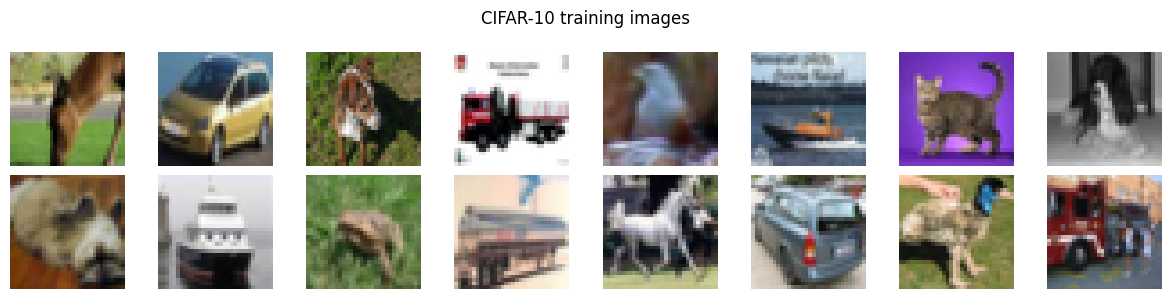

In [3]:
def cifar_dataset(train):
    try:
        return datasets.CIFAR10(str(DATA), train=train, download=True, transform=transforms.ToTensor())
    except (OSError, RuntimeError) as exc:
        # 某些 macOS 的 urllib 系统代理失效，而 curl 可以正常联网。
        import shutil, subprocess
        from torchvision.datasets.utils import check_integrity
        if shutil.which("curl") is None:
            raise RuntimeError("请修复网络/代理，或将官方 CIFAR-10 Python 压缩包放入 DATA 目录。") from exc
        print("自动下载失败，尝试 curl 从官方 HTTPS 下载并校验 MD5:", type(exc).__name__)
        DATA.mkdir(parents=True, exist_ok=True)
        archive = DATA / datasets.CIFAR10.filename
        part = archive.with_suffix(archive.suffix + ".part")
        subprocess.run(["curl", "-L", "--fail", "--retry", "2", "--connect-timeout", "20",
                        "--max-time", "1200", "-o", str(part),
                        "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz"], check=True)
        if not check_integrity(str(part), datasets.CIFAR10.tgz_md5):
            raise RuntimeError("CIFAR-10 压缩包校验失败，请重新下载。")
        part.replace(archive)
        return datasets.CIFAR10(str(DATA), train=train, download=True, transform=transforms.ToTensor())

train_all, test_all = cifar_dataset(True), cifar_dataset(False)
rng = np.random.default_rng(CFG["seed"])
train_idx = rng.permutation(len(train_all))[:CFG["train_size"]]
test_idx = rng.permutation(len(test_all))[:CFG["test_size"]]
train_set, test_set = Subset(train_all, train_idx), Subset(test_all, test_idx)
np.savez(RUN / "split_indices.npz", train=train_idx, test=test_idx)
generator = torch.Generator().manual_seed(CFG["seed"])
def loader(ds, shuffle=False):
    return DataLoader(ds, batch_size=CFG["batch_size"], shuffle=shuffle,
                      num_workers=CFG["num_workers"], pin_memory=device.type=="cuda",
                      generator=generator if shuffle else None)
train_loader = loader(train_set, True)
train_eval_loader, test_loader = loader(train_set), loader(test_set)
classes = train_all.classes
x_example, _ = next(iter(train_eval_loader))
assert x_example.shape[1:] == (3, 32, 32)
assert 0 <= x_example.min() and x_example.max() <= 1
print("训练 / 测试样本:", len(train_set), len(test_set), "输入:", tuple(x_example.shape))
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for ax, x in zip(axes.flat, x_example[:16]):
    ax.imshow(x.permute(1, 2, 0)); ax.axis("off")
fig.suptitle("CIFAR-10 training images"); plt.tight_layout(); plt.show()

## 3. CNN Encoder / Decoder 与 VaDE 目标

Encoder：`3×32×32 → 32×16×16 → 64×8×8 → 128×4×4 → 256 → (μ, log σ²)`。
Decoder：`z → 128×4×4 → 64×8×8 → 32×16×16 → 3×32×32`。

生成过程为 $c\sim Cat(\pi)$、$z\sim N(\mu_c,\mathrm{diag}(\sigma_c^2))$、$x\sim p_\theta(x|z)$。
沿用论文公式 (12)、(16) 和仓库的采样责任度近似：

$$\gamma_c = \mathrm{softmax}_c(\log\pi_c + \log N(z;\mu_c,\mathrm{diag}(\sigma_c^2))).$$

最小化的目标写为：

$$\mathcal L = \mathcal L_{rec} + \sum_c\gamma_c\,KL(q(z|x)\Vert p(z|c)) + \sum_c\gamma_c\log\frac{\gamma_c}{\pi_c}.$$

其中 $KL(q\Vert p_c)=\frac12\sum_j[\log\sigma^2_{cj}-\log\sigma^2_{qj}-1+(\sigma^2_{qj}+(\mu_{qj}-\mu_{cj})^2)/\sigma^2_{cj}]$。这是对应论文与仓库的训练估计式；采样 $p(c|z)$ 是对 $q(c|x)$ 的近似。

连续 RGB 默认采用固定方差 Gaussian 的负对数似然，包含常数项。三项都先对每张图的维度求和，再对 batch 平均，避免误将重建项缩小 3072 倍。`bce` 分支保留原仓库的软像素 BCE 目标用于对照。所有配置均使用 β=1，不加未说明的 KL warm-up。

In [4]:
class Encoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(64, 128, 4, 2, 1), nn.ReLU(),
            nn.Flatten(), nn.Linear(128*4*4, 256), nn.ReLU())
        self.mu = nn.Linear(256, latent_dim)
        self.logvar = nn.Linear(256, latent_dim)
        # AE 阶段仅训练 mu；方差头以小噪声启动，避免直接复制均值权重。
        nn.init.zeros_(self.logvar.weight)
        nn.init.constant_(self.logvar.bias, -4.0)
    def forward(self, x):
        h = self.features(x)
        return self.mu(h), self.logvar(h).clamp(-10, 10)

class Decoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.fc = nn.Linear(latent_dim, 128*4*4)
        self.layers = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, 2, 1))
    def forward(self, z):
        # 返回 logits，BCE 分支用数值稳定的 BCEWithLogits。
        return self.layers(F.relu(self.fc(z)).reshape(-1, 128, 4, 4))

class VaDE(nn.Module):
    def __init__(self, latent_dim=10, n_clusters=10):
        super().__init__()
        self.encoder, self.decoder = Encoder(latent_dim), Decoder(latent_dim)
        self.pi_logits = nn.Parameter(torch.zeros(n_clusters))
        self.mu_c = nn.Parameter(torch.zeros(n_clusters, latent_dim))
        self.logvar_c = nn.Parameter(torch.zeros(n_clusters, latent_dim))
    def responsibilities(self, z):
        lv = self.logvar_c.clamp(-10, 10)
        log_density = -0.5 * (math.log(2*math.pi) + lv[None] +
            (z[:, None] - self.mu_c[None]).square() * (-lv[None]).exp()).sum(-1)
        log_gamma = F.log_softmax(log_density + F.log_softmax(self.pi_logits, 0), dim=1)
        return log_gamma.exp(), log_gamma
    def loss(self, x, likelihood="gaussian", obs_var=0.1):
        mu, lv = self.encoder(x)
        z = mu + torch.randn_like(mu) * (0.5*lv).exp()
        logits = self.decoder(z)
        if likelihood == "bce":
            rec = F.binary_cross_entropy_with_logits(logits, x, reduction="none").flatten(1).sum(1)
        elif likelihood == "gaussian":
            rec = 0.5 * ((x-logits.sigmoid()).square()/obs_var +
                         math.log(2*math.pi*obs_var)).flatten(1).sum(1)
        else:
            raise ValueError(likelihood)
        # 和原仓库一样，用另一份重参数采样估计 gamma。
        zg = mu + torch.randn_like(mu) * (0.5*lv).exp()
        gamma, log_gamma = self.responsibilities(zg)
        prior_lv = self.logvar_c.clamp(-10, 10)
        kl_each = 0.5 * (prior_lv[None] - lv[:, None] - 1 +
            (lv[:, None].exp() + (mu[:, None]-self.mu_c[None]).square()) *
            (-prior_lv[None]).exp()).sum(-1)
        kl_z = (gamma * kl_each).sum(1)
        kl_c = (gamma * (log_gamma - F.log_softmax(self.pi_logits, 0))).sum(1)
        terms = dict(reconstruction=rec.mean(), kl_z=kl_z.mean(), kl_c=kl_c.mean())
        return sum(terms.values()), terms
    @torch.no_grad()
    def predict(self, x):
        mu, _ = self.encoder(x)
        return self.responsibilities(mu)[0].argmax(1)

model = VaDE(CFG["latent_dim"], CFG["n_clusters"]).to(device)
print("参数量:", f"{sum(p.numel() for p in model.parameters()):,}")
with torch.no_grad():
    mu_check, lv_check = model.encoder(x_example[:4].to(device))
    recon_check = model.decoder(mu_check).sigmoid()
assert recon_check.shape == (4, 3, 32, 32)
print("mu/logvar:", tuple(mu_check.shape), "reconstruction:", tuple(recon_check.shape))

参数量: 883,497


mu/logvar: (4, 10) reconstruction: (4, 3, 32, 32)


## 4. 训练与评估工具

ACC 用匈牙利算法寻找簇编号与真实类别之间的一一映射。NMI / ARI 不依赖编号顺序。报告的 test ACC 是聚类惯用的、在该评估集上做最优匹配后的 ACC，**不是**固定类别映射的监督分类准确率。映射仅在评估中使用。

每轮保存模型、优化器、随机数状态与历史记录；每次 Run All 创建新目录，保留之前的实验。默认不自动加载旧检查点，避免误用其他数据/架构的权重。

In [5]:
def clustering_metrics(y, pred):
    y, pred = np.asarray(y, dtype=np.int64), np.asarray(pred, dtype=np.int64)
    w = np.zeros((CFG["n_clusters"], CFG["n_clusters"]), dtype=np.int64)
    np.add.at(w, (pred, y), 1)
    rows, cols = linear_sum_assignment(-w)
    return dict(ACC=float(w[rows, cols].sum()/len(y)),
                NMI=float(normalized_mutual_info_score(y, pred)),
                ARI=float(adjusted_rand_score(y, pred)),
                occupied_clusters=int(np.unique(pred).size)), w

@torch.no_grad()
def encode_data(net, dl):
    net.eval()
    zs, ys = [], []
    for x, y in dl:
        mu, _ = net.encoder(x.to(device))
        zs.append(mu.cpu().numpy()); ys.append(y.numpy())
    return np.concatenate(zs), np.concatenate(ys)

@torch.no_grad()
def evaluate(net, dl):
    net.eval()
    zs, ys, preds = [], [], []
    for x, y in dl:
        mu, _ = net.encoder(x.to(device))
        pred = net.responsibilities(mu)[0].argmax(1)
        zs.append(mu.cpu().numpy()); ys.append(y.numpy()); preds.append(pred.cpu().numpy())
    z, y, pred = np.concatenate(zs), np.concatenate(ys), np.concatenate(preds)
    metrics, counts = clustering_metrics(y, pred)
    return metrics, counts, z, y, pred

def save_checkpoint(filename, stage, epoch, optimizer, history, scheduler=None):
    checkpoint = dict(model=model.state_dict(), config=CFG, mode=MODE,
        stage=stage, epoch=epoch, optimizer=optimizer.state_dict(), history=history,
        scheduler=scheduler.state_dict() if scheduler else None,
        torch_rng=torch.get_rng_state(), numpy_rng=np.random.get_state(),
        python_rng=random.getstate(), loader_rng=generator.get_state(),
        cuda_rng=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        mps_rng=torch.mps.get_rng_state() if device.type=="mps" else None)
    torch.save(checkpoint, RUN / filename)

def checked_step(loss, optimizer, parameters):
    if not torch.isfinite(loss):
        raise FloatingPointError("非有限损失；停止训练，检查数据/学习率/方差。")
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    nn.utils.clip_grad_norm_(parameters, 5.0, error_if_nonfinite=True)
    optimizer.step()

## 5. 阶段 A：卷积 AE 预训练

使用确定性均值 `μ(x)` 重建原图，以像素平均 MSE 训练 encoder / decoder。此阶段先学习图像表征，不更新 GMM 参数与方差头。

In [6]:
ae_parameters = list(model.encoder.parameters()) + list(model.decoder.parameters())
ae_optimizer = torch.optim.Adam(ae_parameters, lr=CFG["pretrain_lr"])
ae_history = []
start = time.perf_counter()
for epoch in range(1, CFG["pretrain_epochs"]+1):
    model.train()
    total = 0.0
    for x, _ in train_loader:  # 不使用类别标签
        x = x.to(device)
        mu, _ = model.encoder(x)
        loss = F.mse_loss(model.decoder(mu).sigmoid(), x)
        checked_step(loss, ae_optimizer, ae_parameters)
        total += loss.item() * len(x)
    row = dict(epoch=epoch, mse=total/len(train_set), seconds=time.perf_counter()-start)
    ae_history.append(row)
    pd.DataFrame(ae_history).to_csv(RUN / "ae_history.csv", index=False)
    save_checkpoint("ae_last.pt", "ae", epoch, ae_optimizer, ae_history)
    print(f"AE {epoch:3d}/{CFG['pretrain_epochs']}  MSE={row['mse']:.5f}", flush=True)

AE   1/50  MSE=0.03201


AE   2/50  MSE=0.02234


AE   3/50  MSE=0.02105


AE   4/50  MSE=0.02073


AE   5/50  MSE=0.02054


AE   6/50  MSE=0.02040


... (40 outputs left out)

AE  47/50  MSE=0.01845


AE  48/50  MSE=0.01844


AE  49/50  MSE=0.01842


AE  50/50  MSE=0.01837


## 6. 阶段 B：GMM 初始化及 AE+GMM 对照

仅在训练图像的潜变量均值上拟合 `GaussianMixture(covariance_type='diag')`，将混合权重、均值、方差复制到可学习的 VaDE 先验。`reg_covar` 避免方差为零。初始化时限制先验 log variance 在训练所用范围内；同样回写 GMM，使两种预测一致。

预训练 AE+GMM 的测试结果作为对照保留，不用来调整训练轮次。

In [7]:
z_train_ae, _ = encode_data(model, train_eval_loader)
z_test_ae, y_test_ae = encode_data(model, test_loader)
gmm = GaussianMixture(n_components=CFG["n_clusters"], covariance_type="diag",
                      n_init=3, max_iter=200, reg_covar=1e-4, random_state=CFG["seed"])
gmm.fit(z_train_ae)
print("GMM converged:", gmm.converged_, "iterations:", gmm.n_iter_)
gmm.covariances_ = np.clip(gmm.covariances_, np.exp(-10), np.exp(10))
gmm.precisions_cholesky_ = 1 / np.sqrt(gmm.covariances_)
gmm.precisions_ = 1 / gmm.covariances_
with torch.no_grad():
    model.pi_logits.copy_(torch.tensor(np.log(gmm.weights_), dtype=torch.float32, device=device))
    model.mu_c.copy_(torch.tensor(gmm.means_, dtype=torch.float32, device=device))
    model.logvar_c.copy_(torch.tensor(np.log(gmm.covariances_), dtype=torch.float32, device=device))
pred_ae = gmm.predict(z_test_ae)
baseline_metrics, _ = clustering_metrics(y_test_ae, pred_ae)
# 确认权重导入及概率计算正确，而不只检查张量尺寸。
with torch.no_grad():
    gamma = model.responsibilities(torch.tensor(z_test_ae[:128], device=device))[0].cpu().numpy()
np.testing.assert_allclose(gamma, gmm.predict_proba(z_test_ae[:128]), atol=2e-4, rtol=2e-4)
np.savez(RUN / "gmm_initial.npz", weights=gmm.weights_, means=gmm.means_, covariances=gmm.covariances_)
torch.save(model.state_dict(), RUN / "initialized_model.pt")
print("AE+GMM test:", baseline_metrics)

GMM converged: True iterations: 22
AE+GMM test: {'ACC': 0.2381, 'NMI': 0.11527804975930855, 'ARI': 0.05590340953476493, 'occupied_clusters': 10}


## 7. 阶段 C：VaDE 联合训练

现在同时更新 CNN、编码方差和 GMM 先验。每轮记录重建项、两项 KL、总损失和学习率；训练中不读取测试标签。`StepLR` 在优化器更新之后调用，避免原仓库旧调用顺序的问题。固定预算结束后使用最后一轮模型。

In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.95)
history = []
start = time.perf_counter()
for epoch in range(1, CFG["epochs"]+1):
    model.train()
    totals = dict(loss=0.0, reconstruction=0.0, kl_z=0.0, kl_c=0.0)
    epoch_lr = optimizer.param_groups[0]["lr"]
    for x, _ in train_loader:
        x = x.to(device)
        loss, terms = model.loss(x, CFG["likelihood"], CFG["obs_var"])
        checked_step(loss, optimizer, model.parameters())
        totals["loss"] += loss.item()*len(x)
        for key, value in terms.items():
            totals[key] += value.item()*len(x)
    scheduler.step()
    row = dict(epoch=epoch, **{k:v/len(train_set) for k,v in totals.items()},
               lr=epoch_lr, seconds=time.perf_counter()-start)
    history.append(row)
    pd.DataFrame(history).to_csv(RUN / "vade_history.csv", index=False)
    save_checkpoint("vade_last.pt", "vade", epoch, optimizer, history, scheduler)
    print(f"VaDE {epoch:3d}/{CFG['epochs']}  loss={row['loss']:.3f}  "
          f"rec={row['reconstruction']:.3f}  KLz={row['kl_z']:.3f}  KLc={row['kl_c']:.3f}", flush=True)

VaDE   1/300  loss=-405.200  rec=-429.541  KLz=22.908  KLc=1.433


VaDE   2/300  loss=-406.626  rec=-431.379  KLz=23.327  KLc=1.425


VaDE   3/300  loss=-407.056  rec=-431.859  KLz=23.381  KLc=1.422


VaDE   4/300  loss=-407.287  rec=-432.120  KLz=23.414  KLc=1.419


VaDE   5/300  loss=-407.486  rec=-432.385  KLz=23.482  KLc=1.418


VaDE   6/300  loss=-407.675  rec=-432.629  KLz=23.537  KLc=1.416


... (290 outputs left out)

VaDE 297/300  loss=-421.239  rec=-447.695  KLz=24.975  KLc=1.481


VaDE 298/300  loss=-421.248  rec=-447.701  KLz=24.973  KLc=1.480


VaDE 299/300  loss=-421.237  rec=-447.686  KLz=24.968  KLc=1.480


VaDE 300/300  loss=-421.268  rec=-447.717  KLz=24.968  KLc=1.480


## 8. 最终评估与结果导出

同时报告训练集（拟合质量）和独立测试集（泛化情况），并列出实际占用的簇数。若只占用很少簇，说明可能发生簇塌缩。ACC 接近随机水平、重建模糊等结果应如实报告，不能以 MNIST 的结果代替 CIFAR-10 实测。

In [9]:
train_metrics, _, _, _, _ = evaluate(model, train_eval_loader)
test_metrics, counts, z_test, y_test, pred_test = evaluate(model, test_loader)
results_table = pd.DataFrame([
    dict(model="AE+GMM", split="test", **baseline_metrics),
    dict(model="VaDE", split="train", **train_metrics),
    dict(model="VaDE", split="test", **test_metrics),
])
display(results_table.round(4))
results_table.to_csv(RUN / "metrics.csv", index=False)
np.savez_compressed(RUN / "test_predictions.npz", indices=test_idx, labels=y_test,
                    clusters=pred_test, latent=z_test, ae_clusters=pred_ae)
summary = dict(mode=MODE, config=CFG, environment=ENV,
    ae_gmm_test=baseline_metrics, vade_train=train_metrics, vade_test=test_metrics,
    gmm_converged=bool(gmm.converged_),
    prediction_rule="argmax p(c|z=encoder_mean)", model_selection="last_epoch",
    status="completed_quick_experiment" if MODE=="quick" else
           "completed_full_experiment" if MODE=="full" else "smoke_only")
(RUN / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2))
print("实际簇计数:", np.bincount(pred_test, minlength=CFG["n_clusters"]))
print("混合权重:", model.pi_logits.softmax(0).detach().cpu().numpy().round(4))

,model,split,ACC,NMI,ARI,occupied_clusters
0,AE+GMM,test,0.2381,0.1153,0.0559,10
1,VaDE,train,0.2443,0.1092,0.0597,10
2,VaDE,test,0.2514,0.1125,0.0626,10


实际簇计数: [1066 1021 2115  705 1543  493  391 1307  360  999]
混合权重: [0.0907 0.113  0.2207 0.069  0.1543 0.0626 0.0467 0.1156 0.0404 0.087 ]


## 9. 曲线、重建、各簇图像和潜空间

所有图片同时展示并保存到本次实验目录。PCA 仅用于将测试潜变量投影到二维，不参与训练或聚类；不同颜色的重叠程度只是定性观察。簇编号不预先对应类别。

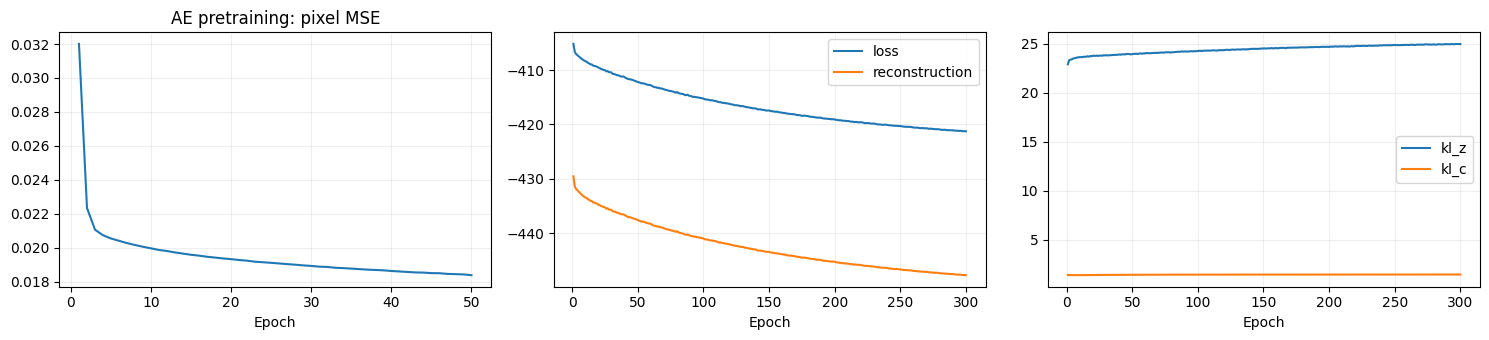

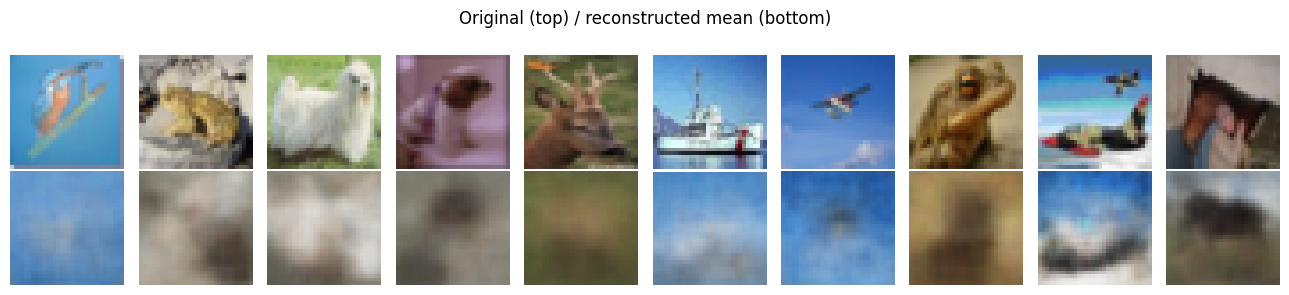

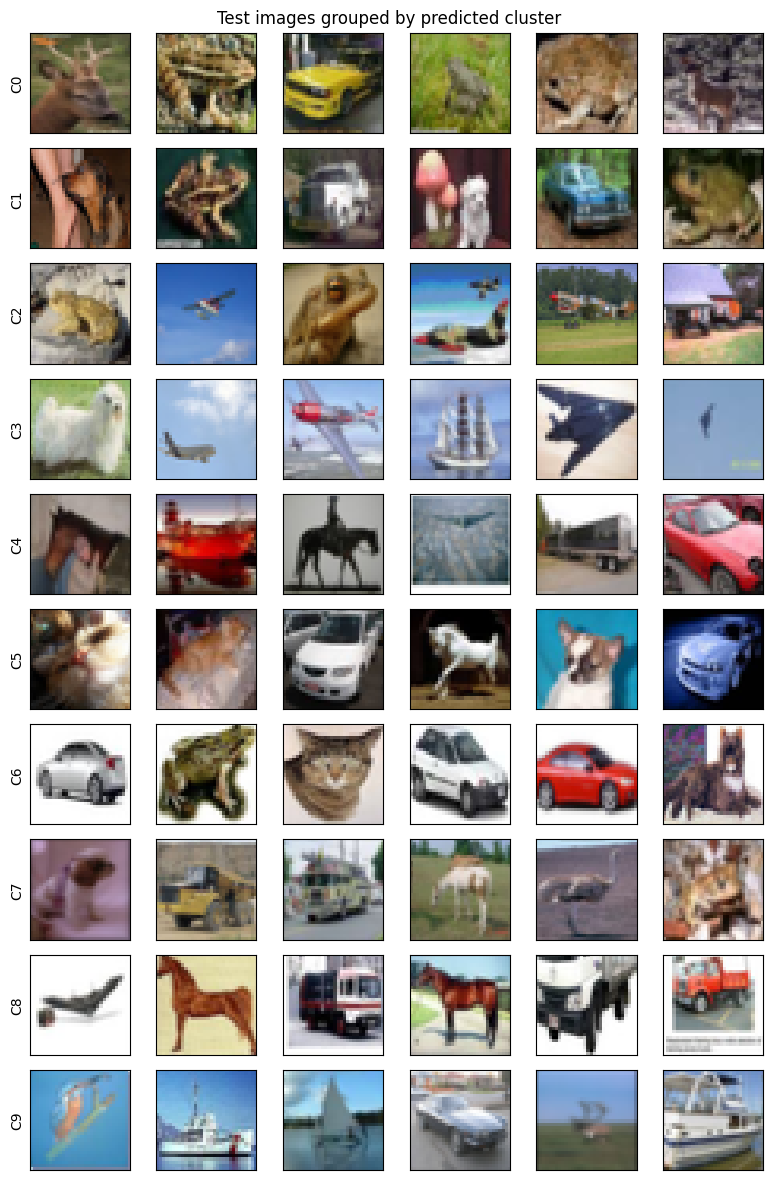

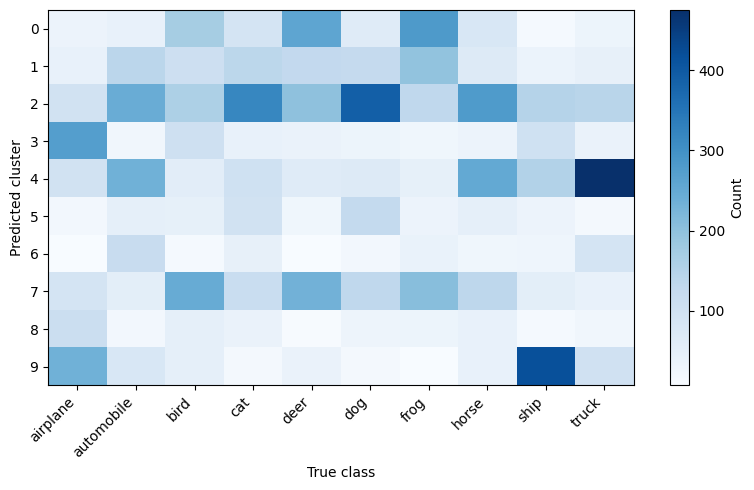

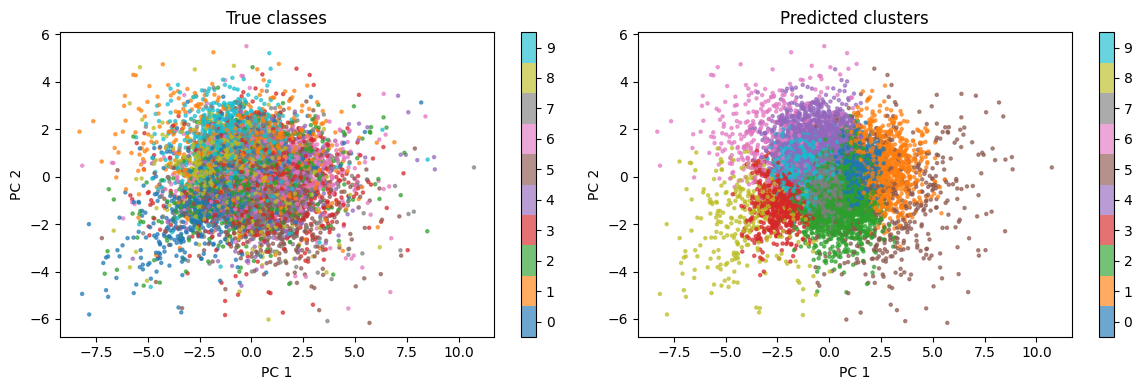

In [10]:
def savefig(name):
    plt.tight_layout()
    plt.savefig(RUN / name, dpi=150, bbox_inches="tight")
    plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
ae_df, va_df = pd.DataFrame(ae_history), pd.DataFrame(history)
axes[0].plot(ae_df.epoch, ae_df.mse); axes[0].set_title("AE pretraining: pixel MSE")
for key in ["loss", "reconstruction"]:
    axes[1].plot(va_df.epoch, va_df[key], label=key)
for key in ["kl_z", "kl_c"]:
    axes[2].plot(va_df.epoch, va_df[key], label=key)
for ax in axes:
    ax.set_xlabel("Epoch"); ax.grid(alpha=0.2)
axes[1].legend(); axes[2].legend()
savefig("loss_curves.png")

model.eval()
x_show, _ = next(iter(test_loader)); x_show = x_show[:10]
with torch.no_grad():
    means, _ = model.encoder(x_show.to(device))
    reconstructed = model.decoder(means).sigmoid().cpu()
fig, axes = plt.subplots(2, 10, figsize=(13, 3))
for j in range(10):
    axes[0,j].imshow(x_show[j].permute(1,2,0)); axes[0,j].axis("off")
    axes[1,j].imshow(reconstructed[j].permute(1,2,0)); axes[1,j].axis("off")
fig.suptitle("Original (top) / reconstructed mean (bottom)")
savefig("reconstructions.png")

# 每行一个簇，展示真实测试图片；空簇明确显示 empty。
fig, axes = plt.subplots(10, 6, figsize=(8, 12))
for c in range(10):
    members = np.flatnonzero(pred_test==c)[:6]
    for j in range(6):
        ax=axes[c,j]; ax.set_xticks([]); ax.set_yticks([])
        if j < len(members):
            x, _ = test_set[int(members[j])]; ax.imshow(x.permute(1,2,0))
        else:
            ax.text(0.5,0.5,"empty",ha="center",va="center")
        if j==0: ax.set_ylabel(f"C{c}")
fig.suptitle("Test images grouped by predicted cluster")
savefig("cluster_examples.png")

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(counts, cmap="Blues", aspect="auto")
ax.set_xticks(range(10), classes, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_ylabel("Predicted cluster"); ax.set_xlabel("True class")
fig.colorbar(im, ax=ax, label="Count")
savefig("cluster_class_counts.png")

embedding = PCA(n_components=2, random_state=CFG["seed"]).fit_transform(z_test)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, labels, title in zip(axes, [y_test, pred_test], ["True classes", "Predicted clusters"]):
    scatter=ax.scatter(embedding[:,0],embedding[:,1],c=labels,cmap="tab10",vmin=-0.5,vmax=9.5,s=5,alpha=0.65)
    ax.set_title(title); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
    fig.colorbar(scatter, ax=ax, ticks=range(10))
savefig("latent_pca.png")

## 10. 从指定混合分量生成图像

对每个簇采样 $z\sim N(\mu_c,\sigma_c^2)$，展示解码器的观测均值。这里不再加入像素层 Gaussian 噪声，因此图中是生成分布的均值图像。每行属于同一混合分量；不能将分量编号直接当作真实类别。

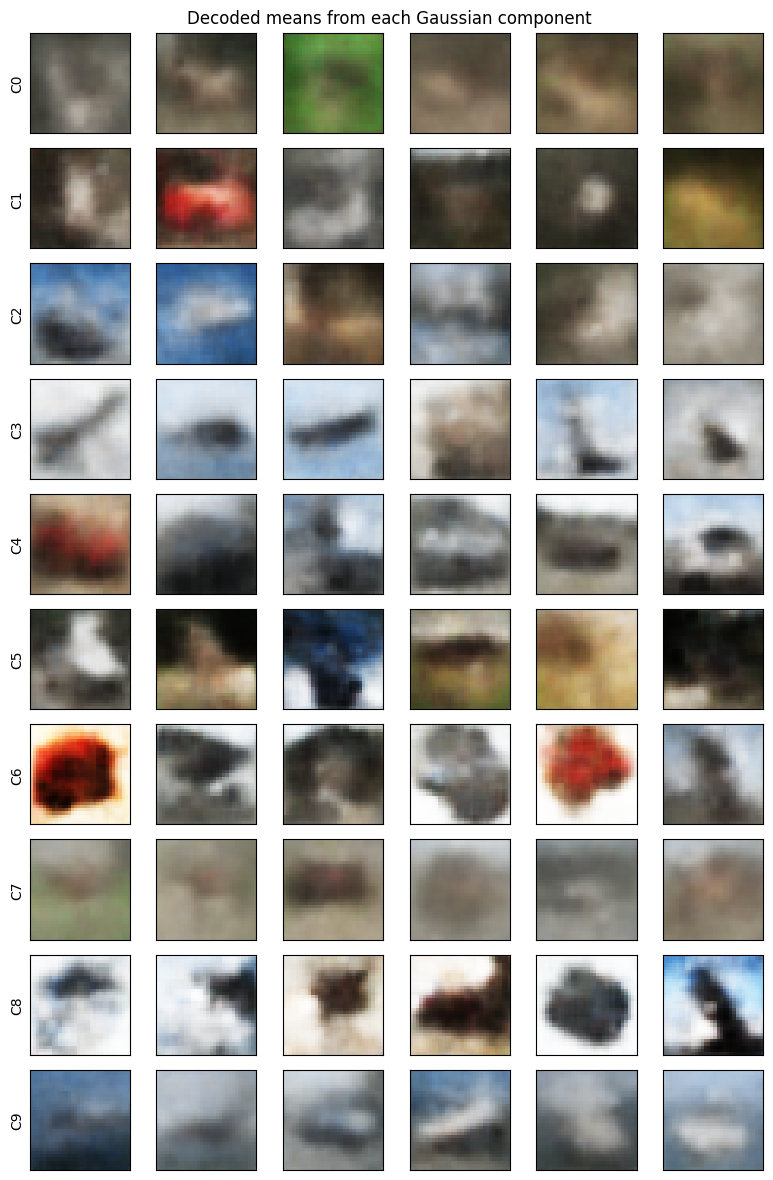

全部结果已保存: /Users/wangfeixuan/Desktop/科研/VADE/results/full_20261117_025603_757775


In [11]:
with torch.no_grad():
    c = torch.arange(10, device=device).repeat_interleave(6)
    z = model.mu_c[c] + torch.randn(60, CFG["latent_dim"], device=device) * (
        0.5*model.logvar_c.clamp(-10,10)[c]).exp()
    generated = model.decoder(z).sigmoid().cpu()
fig, axes = plt.subplots(10, 6, figsize=(8, 12))
for i, ax in enumerate(axes.flat):
    ax.imshow(generated[i].permute(1,2,0)); ax.set_xticks([]); ax.set_yticks([])
    if i%6==0: ax.set_ylabel(f"C{i//6}")
fig.suptitle("Decoded means from each Gaussian component")
savefig("generated_by_cluster.png")
print("全部结果已保存:", RUN)

## 11. 向老师汇报时说明

1. **完成的迁移**：RGB CIFAR-10；CNN encoder / decoder；AE 预训练 → GMM → VaDE 联合优化；全流程无监督训练。
2. **实际规模与指标**：引用本次 `config.json`、`metrics.csv` 和 `summary.json`。`quick` 只代表小规模试跑，不能写成全量收敛结果；正式结果用 `full` 跑完再报告。
3. **比较**：同一数据划分下比较 AE+GMM 与 VaDE 的 ACC/NMI/ARI，联合训练不保证每次都优于预训练表征。检查各簇人数、混淆表、重建和生成图。
4. **原因分析**：CIFAR-10 有背景、姿态和颜色变化。像素重建容易关注颜色和纹理，而十个语义类别不必对应十个高斯分量。低指标或模糊图像是应讨论的实验结果。
5. **后续实验**：固定预算，分别比较 Gaussian / BCE、潜空间维度，以及多个随机种子；如调整超参数，先从训练集建立验证划分，避免根据测试集挑选结果。本 Notebook 只做单种子迁移基线，未提供多次实验的均值/标准差。

### 来源追踪

- 原仓库：[model.py](https://github.com/GuHY777/VaDE-pytorch/blob/master/model.py)、[main.py](https://github.com/GuHY777/VaDE-pytorch/blob/master/main.py)、[dataloader.py](https://github.com/GuHY777/VaDE-pytorch/blob/master/dataloader.py)。
- 检查的 Git blob：model `4bbd45b2c9ae420b57e6b07332184b980006fba8`；main `617cd2d8f6def4f74d431c772d800cd809c7921a`；dataloader `6b0836a5619beec431cbf58bbaad39af24cf3dbc`。
- 本目录老师提供的 Jiang et al. PDF，第 6–7 页公式 (12)、(16)；固定观测方差是本迁移实验的简化，论文连续观测模型允许预测方差。
- 数据：[CIFAR-10 官方页面](https://www.cs.toronto.edu/~kriz/cifar.html)。